# Portfolio Optimization: Markowitz and Black-Litterman on 10 ETFs

## Problem
An allocator must split capital across ten liquid ETFs (US equity, international equity, bonds, gold, commodities, real estate). Mean-variance optimisation is very sensitive to estimation error in expected returns and covariances. The notebook compares naive and optimised allocations, uses Ledoit-Wolf covariance shrinkage and Black-Litterman views, and tests which approach held up out of sample when rebalanced once a year.

## Data
Source: Yahoo Finance via `yfinance`. Daily adjusted closes for SPY, QQQ, IWM, EFA, EEM, TLT, IEF, GLD, DBC and VNQ, from 2015-01-01 to the run date (2026-11-19). Today's bar is dropped because the session may be incomplete. Fund total assets (`totalAssets`, used as the market-cap-style prior) are read from the same source at run time. These are the current figures, not point-in-time history.

## Method
Let $r_t$ be daily simple returns and $w$ the weights, with $\sum_i w_i = 1$ and $w_i \ge 0$. Annualisation uses 252 trading days. The risk-free rate is set to 0.

**Covariance.** The sample covariance is shrunk toward a constant-correlation target with Ledoit-Wolf (2004), $\hat\Sigma = (1-\delta)S + \delta\,\mu_0 I$, where the shrinkage intensity $\delta$ is estimated from the data.

**Markowitz.** Minimum variance solves $\min_w w^\top\Sigma w$. Maximum Sharpe solves $\max_w \dfrac{w^\top\mu}{\sqrt{w^\top\Sigma w}}$. Both are long-only with $w_i \le 1$ and are solved with SLSQP. The efficient frontier is the set of minimum-variance portfolios for target returns $w^\top\mu = m$.

**Black-Litterman.** The market-cap-style prior weights $w_{\rm mkt}$ are fund total assets normalised to sum to 1. The implied equilibrium returns are $\Pi = \delta\,\Sigma w_{\rm mkt}$ with risk aversion $\delta = 2.5$. Views are $P\mu = Q + \varepsilon$, $\varepsilon \sim N(0,\Omega)$, with $\Omega = \mathrm{diag}(P\,\tau\Sigma\,P^\top)$ and $\tau = 0.05$. The posterior is

$$\mu_{BL} = \big[(\tau\Sigma)^{-1} + P^\top\Omega^{-1}P\big]^{-1}\big[(\tau\Sigma)^{-1}\Pi + P^\top\Omega^{-1}Q\big], \qquad \Sigma_{BL} = \Sigma + \big[(\tau\Sigma)^{-1} + P^\top\Omega^{-1}P\big]^{-1}$$

Two views are stated:
1. Relative: QQQ outperforms SPY by 2.0% per year.
2. Absolute: GLD returns 5.0% per year.

**Out-of-sample backtest.** Each year $Y$ from 2018 to 2026, the weights are estimated on the three prior calendar years $[Y-3, Y)$. They are held through year $Y$ (buy-and-hold with weights drifting between rebalances) and reset on the first trading day of the next year. Strategies: equal weight (EW), minimum variance (MinVar), maximum Sharpe on historical means (MaxSharpe), and maximum Sharpe on Black-Litterman posterior means (BL). The reported metrics are CAGR, annualised volatility, Sharpe ratio (rf = 0), maximum drawdown and average one-way turnover at rebalance.

In [1]:
import datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.optimize import minimize
from sklearn.covariance import LedoitWolf

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.figsize': (10, 4.8), 'axes.grid': True})

ETFS = ['SPY', 'QQQ', 'IWM', 'EFA', 'EEM', 'TLT', 'IEF', 'GLD', 'DBC', 'VNQ']
TODAY = pd.Timestamp(dt.date.today())
TRADING_DAYS = 252

raw = yf.download(ETFS, start='2015-01-01', auto_adjust=False, progress=False)
px_all = raw['Adj Close'][ETFS]
px = px_all[px_all.index < TODAY].dropna()
print(f"Raw rows {len(px_all)}, after dropping today's bar and missing values {len(px)}")
print(f"Price sample: {px.index[0].date()} to {px.index[-1].date()}")
rets = px.pct_change().dropna()
print(f"Return observations: {len(rets)}")

Raw rows 2989, after dropping today's bar and missing values 2988
Price sample: 2015-01-02 to 2026-11-18
Return observations: 2987


In [2]:
aum = pd.Series({tk: yf.Ticker(tk).info.get('totalAssets', np.nan) for tk in ETFS})
if aum.isna().any():
    raise RuntimeError(f"Missing totalAssets for: {list(aum[aum.isna()].index)}")
w_mkt = aum / aum.sum()
print(pd.DataFrame({'total_assets_$bn': aum / 1e9, 'prior_weight': w_mkt}).round(4).to_string())

     total_assets_$bn  prior_weight
SPY          796.8652        0.4594
QQQ          463.8336        0.2674
IWM           75.4919        0.0435
EFA           76.6150        0.0442
EEM           28.2467        0.0163
TLT           47.5186        0.0274
IEF           43.5294        0.0251
GLD          131.0096        0.0755
DBC            1.9433        0.0011
VNQ           69.4587        0.0400


     ann_return_hist  ann_vol_sample  ann_vol_LW
SPY           0.1388          0.1754      0.1755
QQQ           0.1882          0.2200      0.2196
IWM           0.1069          0.2228      0.2224
EFA           0.0861          0.1721      0.1722
EEM           0.0772          0.2109      0.2106
TLT           0.0000          0.1472      0.1475
IEF           0.0115          0.0654      0.0673
GLD           0.1059          0.1640      0.1642
DBC           0.0711          0.1801      0.1801
VNQ           0.0721          0.2014      0.2011
Ledoit-Wolf shrinkage intensity: 0.0090


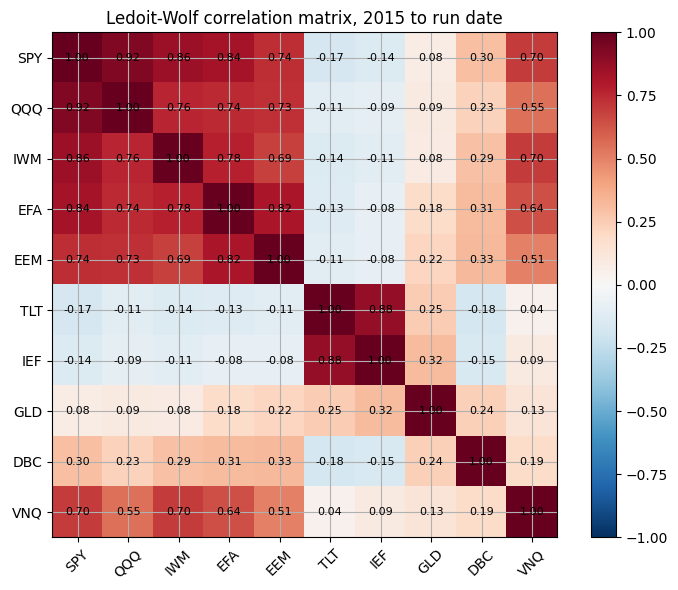

In [3]:
def lw_cov(r):
    lw = LedoitWolf().fit(r.values)
    cov = pd.DataFrame(lw.covariance_ * TRADING_DAYS, index=ETFS, columns=ETFS)
    return cov, lw.shrinkage_

def ann_mu(r):
    return r.mean() * TRADING_DAYS

cov_full, shrink_full = lw_cov(rets)
mu_full = ann_mu(rets)
sample_vol = rets.std() * np.sqrt(TRADING_DAYS)
lw_vol = pd.Series(np.sqrt(np.diag(cov_full)), index=ETFS)
stats_tbl = pd.DataFrame({'ann_return_hist': mu_full, 'ann_vol_sample': sample_vol, 'ann_vol_LW': lw_vol})
print(stats_tbl.round(4).to_string())
print(f"Ledoit-Wolf shrinkage intensity: {shrink_full:.4f}")

corr = pd.DataFrame(cov_full.values / np.outer(lw_vol, lw_vol), index=ETFS, columns=ETFS)
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(ETFS))); ax.set_xticklabels(ETFS, rotation=45)
ax.set_yticks(range(len(ETFS))); ax.set_yticklabels(ETFS)
for i in range(len(ETFS)):
    for j in range(len(ETFS)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha='center', va='center', fontsize=8)
ax.set_title('Ledoit-Wolf correlation matrix, 2015 to run date')
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

In [4]:
N = len(ETFS)
CONS = ({'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0},)
BOUNDS = [(0.0, 1.0)] * N

def _slsqp(fun, x0, extra=()):
    res = minimize(fun, x0, method='SLSQP', bounds=BOUNDS, constraints=CONS + tuple(extra),
                   options={'maxiter': 1000, 'ftol': 1e-12})
    if not res.success:
        raise RuntimeError(res.message)
    return res.x

def min_var(cov):
    return _slsqp(lambda w: w @ cov @ w, np.ones(N) / N)

def max_sharpe(mu, cov, rf=0.0):
    def neg_sharpe(w):
        return -(w @ mu - rf) / np.sqrt(w @ cov @ w)
    return _slsqp(neg_sharpe, np.ones(N) / N)

def min_var_for_return(mu, cov, target):
    cons = ({'type': 'eq', 'fun': lambda w: w @ mu - target},)
    return _slsqp(lambda w: w @ cov @ w, np.ones(N) / N, extra=cons)

def port_stats(w, mu, cov):
    return w @ mu, np.sqrt(w @ cov @ w)

w_ew = np.ones(N) / N
w_mv = min_var(cov_full.values)
w_ms = max_sharpe(mu_full.values, cov_full.values)
w_mkt_v = w_mkt.values

wt = pd.DataFrame({'equal_weight': w_ew, 'min_var_LW': w_mv, 'max_sharpe_hist': w_ms,
                   'market_prior': w_mkt_v}, index=ETFS)
print("Weights (full-sample, long-only):")
print(wt.round(4).to_string())
for name, w in [('equal_weight', w_ew), ('min_var_LW', w_mv), ('max_sharpe_hist', w_ms)]:
    r_, v_ = port_stats(w, mu_full.values, cov_full.values)
    print(f"{name:>16}: in-sample expected return {r_:.4f}, volatility {v_:.4f}, Sharpe {r_/v_:.3f}")

Weights (full-sample, long-only):
     equal_weight  min_var_LW  max_sharpe_hist  market_prior
SPY           0.1      0.1047           0.0000        0.4594
QQQ           0.1      0.0000           0.4114        0.2674
IWM           0.1      0.0000           0.0000        0.0435
EFA           0.1      0.0063           0.0000        0.0442
EEM           0.1      0.0000           0.0000        0.0163
TLT           0.1      0.0000           0.0000        0.0274
IEF           0.1      0.7799           0.1637        0.0251
GLD           0.1      0.0000           0.3580        0.0755
DBC           0.1      0.1090           0.0669        0.0011
VNQ           0.1      0.0000           0.0000        0.0400
    equal_weight: in-sample expected return 0.0858, volatility 0.1167, Sharpe 0.735
      min_var_LW: in-sample expected return 0.0318, volatility 0.0563, Sharpe 0.565
 max_sharpe_hist: in-sample expected return 0.1220, volatility 0.1177, Sharpe 1.036


In [5]:
DELTA = 2.5        # risk aversion used to back out equilibrium returns
TAU_BL = 0.05      # scale of prior uncertainty
# View 1 (relative): QQQ outperforms SPY by 2.0% per year
# View 2 (absolute): GLD returns 5.0% per year
P = np.zeros((2, N))
P[0, ETFS.index('QQQ')] = 1.0;  P[0, ETFS.index('SPY')] = -1.0
P[1, ETFS.index('GLD')] = 1.0
Q = np.array([0.02, 0.05])

def bl_posterior(cov, w_prior, P=P, Q=Q):
    Pi = DELTA * cov @ w_prior
    tcov = TAU_BL * cov
    Omega = np.diag(np.diag(P @ tcov @ P.T))
    inv_tcov = np.linalg.inv(tcov)
    M = np.linalg.inv(inv_tcov + P.T @ np.linalg.inv(Omega) @ P)
    mu_bl = M @ (inv_tcov @ Pi + P.T @ np.linalg.inv(Omega) @ Q)
    return Pi, mu_bl, cov + M, Omega

Pi, mu_bl, cov_bl, Omega = bl_posterior(cov_full.values, w_mkt_v)
w_bl = max_sharpe(mu_bl, cov_bl)
bl_tbl = pd.DataFrame({'implied_eq_return_Pi': Pi, 'hist_mu': mu_full.values, 'BL_posterior_mu': mu_bl,
                       'w_BL_maxSharpe': w_bl, 'w_market_prior': w_mkt_v}, index=ETFS)
print(bl_tbl.round(4).to_string())
print(f"View 1 (QQQ - SPY) prior-implied spread {Pi[ETFS.index('QQQ')] - Pi[ETFS.index('SPY')]:.4f}, "
      f"posterior spread {mu_bl[ETFS.index('QQQ')] - mu_bl[ETFS.index('SPY')]:.4f} (stated view 0.0200)")
print(f"View 2 (GLD) posterior return {mu_bl[ETFS.index('GLD')]:.4f} (stated view 0.0500)")
print("View uncertainty (Omega diagonal, std dev):", np.round(np.sqrt(np.diag(Omega)), 4))

     implied_eq_return_Pi  hist_mu  BL_posterior_mu  w_BL_maxSharpe  w_market_prior
SPY                0.0693   0.1388           0.0721          0.2579          0.4594
QQQ                0.0844   0.1882           0.0900          0.3056          0.2674
IWM                0.0767   0.1069           0.0799          0.0337          0.0435
EFA                0.0585   0.0861           0.0629          0.0342          0.0442
EEM                0.0659   0.0772           0.0727          0.0126          0.0163
TLT               -0.0051   0.0000          -0.0007          0.0212          0.0274
IEF               -0.0014   0.0115           0.0011          0.0195          0.0251
GLD                0.0121   0.1059           0.0312          0.2833          0.0755
DBC                0.0213   0.0711           0.0261          0.0009          0.0011
VNQ                0.0564   0.0721           0.0592          0.0310          0.0400
View 1 (QQQ - SPY) prior-implied spread 0.0152, posterior spread 0.0180 (sta

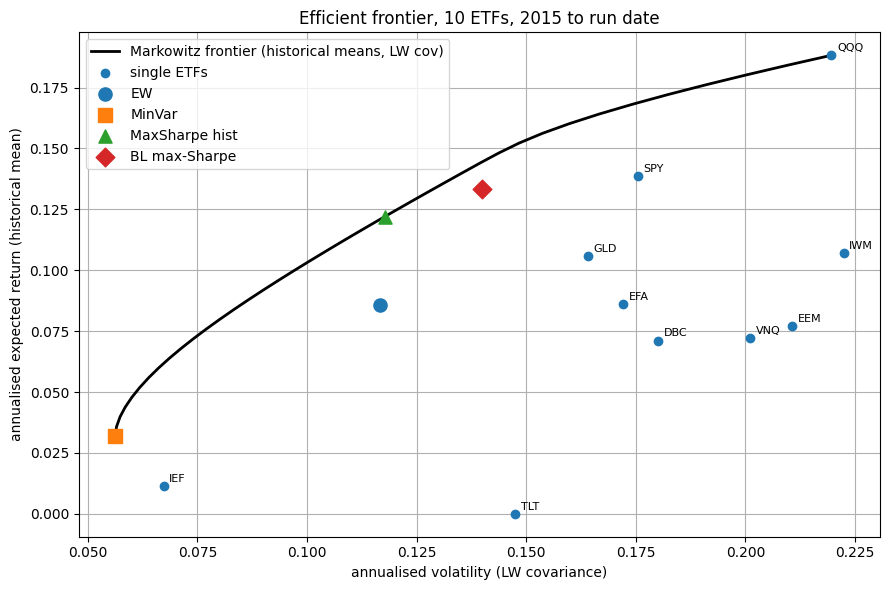

BL max-Sharpe portfolio on historical means: return 0.1334, vol 0.1399
Frontier points computed: 40 of 40


In [6]:
mu_grid_lo = port_stats(w_mv, mu_full.values, cov_full.values)[0]
targets = np.linspace(mu_grid_lo, mu_full.max(), 40)
front = []
for m in targets:
    try:
        w = min_var_for_return(mu_full.values, cov_full.values, m)
        front.append(port_stats(w, mu_full.values, cov_full.values))
    except RuntimeError:
        pass
front = np.array(front)

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(front[:, 1], front[:, 0], 'k-', lw=2, label='Markowitz frontier (historical means, LW cov)')
ax.scatter(np.sqrt(np.diag(cov_full)), mu_full, c='tab:blue', zorder=3, label='single ETFs')
for name, w, mk in [('EW', w_ew, 'o'), ('MinVar', w_mv, 's'), ('MaxSharpe hist', w_ms, '^'), ('BL max-Sharpe', w_bl, 'D')]:
    r_, v_ = port_stats(w, mu_full.values, cov_full.values)
    ax.scatter(v_, r_, marker=mk, s=90, zorder=4, label=name)
for tk in ETFS:
    ax.annotate(tk, (np.sqrt(cov_full.loc[tk, tk]), mu_full[tk]), fontsize=8, xytext=(4, 3), textcoords='offset points')
ax.set_xlabel('annualised volatility (LW covariance)')
ax.set_ylabel('annualised expected return (historical mean)')
ax.set_title('Efficient frontier, 10 ETFs, 2015 to run date')
ax.legend()
plt.tight_layout()
plt.show()
r_bl_hist, v_bl_hist = port_stats(w_bl, mu_full.values, cov_full.values)
print(f"BL max-Sharpe portfolio on historical means: return {r_bl_hist:.4f}, vol {v_bl_hist:.4f}")
print(f"Frontier points computed: {len(front)} of {len(targets)}")

In [7]:
TEST_YEARS = list(range(2018, TODAY.year + 1))

def strategy_weights(method, train):
    if method == 'EW':
        return np.ones(N) / N
    cov, _ = lw_cov(train)
    cov = cov.values
    if method == 'MinVar':
        return min_var(cov)
    mu = ann_mu(train).values
    if method == 'MaxSharpe':
        return max_sharpe(mu, cov)
    if method == 'BL':
        _, mu_b, cov_b, _ = bl_posterior(cov, w_mkt_v)
        return max_sharpe(mu_b, cov_b)
    raise ValueError(method)

def backtest(method):
    level, pieces, drift, turnovers, w_log = 1.0, [], None, [], {}
    for Y in TEST_YEARS:
        train = rets[(rets.index >= f'{Y-3}-01-01') & (rets.index < f'{Y}-01-01')]
        test = rets[rets.index.year == Y]
        if len(test) == 0:
            continue
        w = strategy_weights(method, train)
        w_log[Y] = w
        if drift is not None:
            turnovers.append(0.5 * np.abs(w - drift).sum())
        growth = (1 + test).cumprod().values
        vals = level * (growth @ w)
        pieces.append(pd.Series(vals, index=test.index))
        level = vals[-1]
        drift = w * growth[-1] / (growth[-1] @ w)
    return pd.concat(pieces), w_log, float(np.mean(turnovers))

def metrics(vals):
    v = np.concatenate([[1.0], vals.values])
    r = v[1:] / v[:-1] - 1
    years = len(r) / TRADING_DAYS
    cagr = v[-1] ** (1 / years) - 1
    vol = r.std(ddof=1) * np.sqrt(TRADING_DAYS)
    sharpe = r.mean() * TRADING_DAYS / vol
    mdd = np.min(v / np.maximum.accumulate(v) - 1)
    return dict(CAGR=cagr, ann_vol=vol, Sharpe_rf0=sharpe, max_drawdown=mdd, total_return=v[-1] - 1)

METHODS = {'EW': 'Equal weight', 'MinVar': 'Min variance (LW)', 'MaxSharpe': 'Max Sharpe (hist mean)',
           'BL': 'Black-Litterman max Sharpe'}
bt, wlog, turn = {}, {}, {}
for m in METHODS:
    bt[m], wlog[m], turn[m] = backtest(m)

tbl = pd.DataFrame({METHODS[m]: metrics(bt[m]) for m in METHODS}).T
tbl['avg_one_way_turnover'] = [turn[m] for m in METHODS]
print(f"Out-of-sample test period: {bt['EW'].index[0].date()} to {bt['EW'].index[-1].date()}, yearly rebalance")
print(tbl.round(4).to_string())

Out-of-sample test period: 2018-01-02 to 2026-11-18, yearly rebalance
                              CAGR  ann_vol  Sharpe_rf0  max_drawdown  total_return  avg_one_way_turnover
Equal weight                0.0834   0.1222      0.7173       -0.2241        1.0341                0.0488
Min variance (LW)           0.0346   0.0597      0.6000       -0.1593        0.3518                0.0612
Max Sharpe (hist mean)      0.0822   0.1232      0.7032       -0.2161        1.0136                0.3963
Black-Litterman max Sharpe  0.1397   0.1433      0.9842       -0.2404        2.1858                0.1423


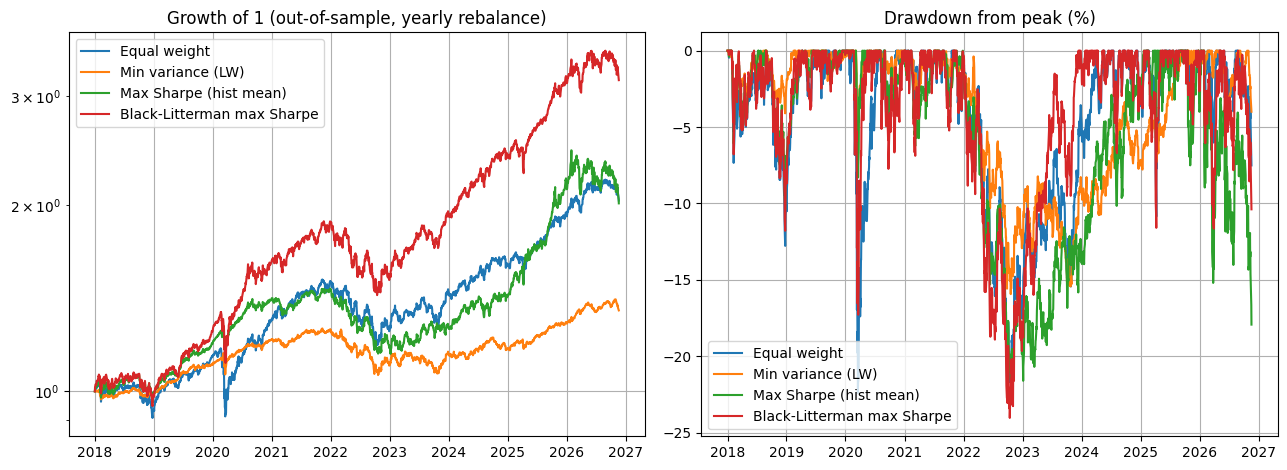

      Equal weight  Min variance (LW)  Max Sharpe (hist mean)  Black-Litterman max Sharpe
Date                                                                                     
2018         -6.52              -1.13                   -0.62                       -1.23
2019         21.66              11.58                   20.09                       26.62
2020         15.19              10.01                   18.55                       30.32
2021         14.83               3.47                    3.16                       15.18
2022        -16.03             -12.12                  -18.85                      -18.18
2023         14.99               4.40                    7.38                       26.69
2024          9.68               1.71                   11.95                       22.54
2025         20.40               9.84                   49.04                       32.06
2026          6.03               5.02                   -5.10                        1.17

Equal wei

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for m in METHODS:
    v = pd.concat([pd.Series([1.0], index=[bt[m].index[0] - pd.Timedelta(days=1)]), bt[m]])
    axes[0].plot(v.index, v.values, label=METHODS[m])
    dd = v / v.cummax() - 1
    axes[1].plot(dd.index, dd.values * 100, label=METHODS[m])
axes[0].set_yscale('log'); axes[0].set_title('Growth of 1 (out-of-sample, yearly rebalance)'); axes[0].legend()
axes[1].set_title('Drawdown from peak (%)'); axes[1].legend()
plt.tight_layout()
plt.show()

yr = {}
for m in METHODS:
    s = bt[m]
    end_level = s.groupby(s.index.year).last()
    prev = end_level.shift(1).fillna(1.0)
    yr[METHODS[m]] = end_level / prev - 1
print((pd.DataFrame(yr) * 100).round(2).to_string())
print()
for m in METHODS:
    print(f"{METHODS[m]} weights at last rebalance ({TEST_YEARS[-1]}):",
          dict(zip(ETFS, np.round(wlog[m][TEST_YEARS[-1]], 3))))

## Results
All numbers are from the executed cells above (price sample 2015-01-02 to 2026-11-18, 2,987 daily returns; the Ledoit-Wolf shrinkage intensity is 0.0090, so the shrinkage is light).

- **Prior weights (fund total assets, run date):** SPY 45.9%, QQQ 26.7%, GLD 7.6%, IWM 4.4%, EFA 4.4%, VNQ 4.0%, TLT 2.7%, IEF 2.5%, EEM 1.6%, DBC 0.1%.
- **Historical annual returns (mean x 252):** QQQ 18.8%, SPY 13.9%, IWM 10.7%, GLD 10.6%, EFA 8.6%, VNQ 7.2%, DBC 7.1%, EEM 7.7%, IEF 1.2%, TLT 0.0%. Annual vol ranges from 6.7% (IEF) to 22.3% (IWM).
- **Min variance (full sample):** expected return 3.2%, volatility 5.6%. The weights are IEF 78.0%, DBC 10.9%, SPY 10.5%.
- **Max Sharpe on historical means (full sample, in-sample):** return 12.2%, volatility 11.8%, Sharpe 1.04. The weights are QQQ 41.1%, GLD 35.8%, IEF 16.4%, DBC 6.7%. Equal weight gives an in-sample Sharpe of 0.735.
- **Black-Litterman:** the prior-implied QQQ minus SPY spread is 1.5%, and the posterior spread is 1.8% against the 2.0% view. The posterior GLD return is 3.1% against the 5.0% view, because the view is shrunk toward the prior. The max-Sharpe BL weights are SPY 25.8%, QQQ 30.6%, GLD 28.3%.
- **Out-of-sample backtest, 2018 to 2026-11-18, yearly rebalance (Sharpe with rf = 0):**
  - Equal weight: CAGR 8.34%, vol 12.22%, Sharpe 0.717, max drawdown -22.4%, turnover 4.9%.
  - Min variance (LW): CAGR 3.46%, vol 5.97%, Sharpe 0.600, max drawdown -15.9%, turnover 6.1%.
  - Max Sharpe (historical means): CAGR 8.22%, vol 12.32%, Sharpe 0.703, max drawdown -21.6%, turnover 39.6%.
  - Black-Litterman max Sharpe: CAGR 13.97%, vol 14.33%, Sharpe 0.984, max drawdown -24.0%, turnover 14.2%.
- **Year-by-year:** in 2022 BL lost 18.2% against 16.0% for equal weight. In 2025 max Sharpe on historical means gained 49.0%, the best single year for any strategy.
- **Caveats.** (1) The BL backtest is not a clean out-of-sample test. The prior weights are the current fund sizes, which already reflect the SPY and QQQ growth of 2018 to 2026, and the QQQ-over-SPY view was written with that history known. The BL Sharpe and return should be read as an upper bound. (2) The view values are assumptions, not forecasts. (3) Rf = 0, so Sharpe ratios are excess-return ratios against zero. (4) The max-Sharpe and BL weights are concentrated, which is a known feature of unconstrained mean-variance results. (5) Every SLSQP call returned success, so no optimisation failed.

## Conclusions
1. **Optimising in-sample overstates what you can earn.** On the full sample, the max-Sharpe portfolio looks excellent (Sharpe 1.04 against 0.735 for equal weight), concentrated in QQQ (41%) and gold (36%). Out of sample, with yearly rebalancing from 2018, the same method delivers Sharpe 0.703 against 0.717 for equal weight, with 40% yearly turnover. Markowitz maximises estimation error: a historical-mean input is noise.
2. **Minimum variance is the defensive choice, not the best one.** It has the lowest risk (6.0% annual volatility) and the smallest drawdown (-15.9%), but concentrates 70% to 78% in intermediate Treasuries and earns a CAGR of only 3.5% (Sharpe 0.600).
3. **Black-Litterman gave the best backtest, but it is not a clean test.** Its out-of-sample Sharpe is 0.984 (CAGR 14.0%, drawdown -24.0%) against 0.717 for equal weight. However, the two views (QQQ beats SPY by 2% per year, gold returns 5%) were written with hindsight in a period in which both did very well, the prior uses current fund sizes as market weights, and the views were fixed for every year. Treat the result as an upper bound that shows how strongly the method depends on its views, not as evidence of skill.
4. **The method behaves sensibly.** The posterior return for a view is a compromise between the prior and the view: the QQQ minus SPY spread goes from 1.5% (prior) to 1.8% (view 2.0%), and the gold return from 1.2% to 3.1% (view 5.0%), because the view's uncertainty is large. Ledoit-Wolf shrinkage was light (intensity 0.009) because there are 2,987 daily observations for 10 assets.
5. **Limits.** Long-only constraints, no transaction costs or taxes, a risk-free rate of 0, one set of views, yearly rebalancing and a single historical path (2018 to 2026 included a strong equity market).

**Takeaway for the interview:** the lesson of this project is not which portfolio won, but that expected returns are the fragile input; Black-Litterman makes that input explicit through the views, so you have to be honest about where the views come from.